# Audit et validation des données financières

**Objectif** : Vérifier la disponibilité, l'intégrité et la qualité des données de marché 
avant la construction et le backtest des portefeuilles A, B, C et D.

**Actifs analysés** : 
- **SPY** : Actions américaines (S&P 500)
- **IEF** : Obligations d'État US à 7–10 ans
- **GLD** : Or physique
- **BIL** : Trésorerie (Bons du Trésor US à 1–3 mois)

**Période d'étude** : Juin 2007 à Décembre 2025 (cours quotidiens en dollars).

In [1]:
import sys
from pathlib import Path

# On indique à Python où trouver le dossier src/
sys.path.append(str(Path.cwd().parent))

# On importe la fonction
from src.data_scraping import fetch_and_save_data

# On charge les prix
prices = fetch_and_save_data()
prices.head()

Chargement des données depuis : /home/onyxia/work/Projet-Python-ENSAE/data/raw/asset_prices.parquet


Ticker,BIL,GLD,IEF,SPY
Date,,,,
2007-06-01,69.976288,66.440002,49.776043,107.917862
2007-06-04,69.991547,66.540001,49.855808,107.931854
2007-06-05,69.991547,66.370003,49.696266,107.504662
2007-06-06,70.022125,66.410004,49.720852,106.348984
2007-06-07,70.006813,65.260002,49.223785,104.429848


In [6]:
# 1. Vérifier qu'il n'y a aucun trou (valeurs manquantes)
# Y a-t-il AU MOINS UNE valeur manquante (trou) ?
if prices.isna().any().any():
    print("Il y a des valeurs manquantes dans les données")
else:
    print("Aucune valeur manquante détectée")

# 2. Vérifier que tous les prix sont bien strictement positifs
if (prices <= 0).any().any():
    print("Il y a au moins un prix négatif ou nul")
else:
    print("Tous les prix sont positifs et cohérents")

Aucune valeur manquante détectée
Tous les prix sont positifs et cohérents


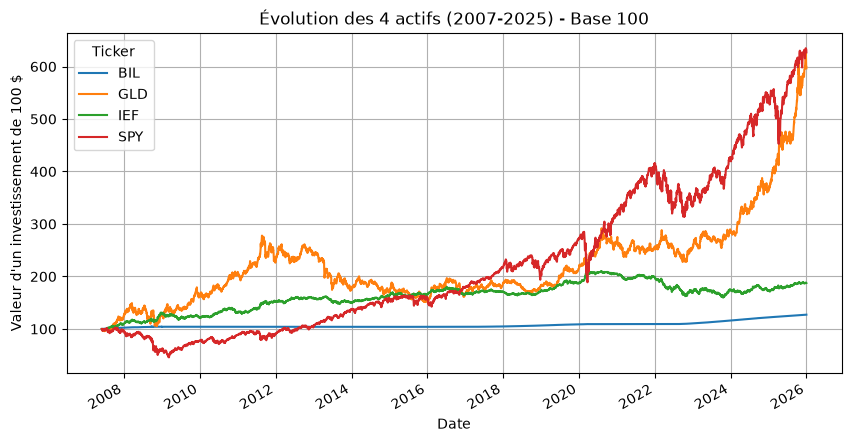

In [4]:
import matplotlib.pyplot as plt

# 1. On ramène tous les actifs à 100 au départ
base_100 = (prices / prices.iloc[0]) * 100

# 2. On trace le graphique
base_100.plot(figsize=(10, 5))
plt.title("Évolution des 4 actifs (2007-2025) - Base 100")
plt.ylabel("Valeur d'un investissement de 100 $")
plt.grid(True)
plt.show()